<a href="https://colab.research.google.com/github/TIMMY-AKLIS-SURESH/ECG_Project/blob/main/notebook18e80b3843.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

mahvishfatma_ecg_combined_dataset_path = kagglehub.dataset_download('mahvishfatma/ecg-combined-dataset')
mahvishfatma_holdout_test_set_path = kagglehub.dataset_download('mahvishfatma/holdout-test-set')

print('Data source import complete.')


# ECG Image Classification (4 classes) - Pretrained ConvNeXt-Nano (~15.6M params), 640x1184 input

**Classes:** `0_MI`, `1_History_MI`, `2_Abnormal`, `3_Normal`

Key changes vs. the old scripts:
1. **Pretrained ImageNet weights** (old code used `pretrained=False`, i.e. training from scratch on ~3,200 images).
2. Plain classification head from timm, with stochastic depth + dropout for regularization.
3. ECG-safe augmentation (small shifts/scale/rotation, brightness/contrast, blur) - no flips.
4. Stratified split, warmup + cosine LR, layer-wise LR (small for backbone, larger for head), EMA of weights, early stopping.
5. The holdout set is used **only once at the end** (never for model selection).

Folder layout expected (paths are auto-detected on Kaggle; no editing needed):
```
ECG_Combined_Dataset/{0_MI,1_History_MI,2_Abnormal,3_Normal}/*.png
Holdout_Test_Set/{0_MI,1_History_MI,2_Abnormal,3_Normal}/*.png
```

**Kaggle checklist:** Accelerator = GPU (T4 x2 or P100), Internet = On (needed once to download pretrained weights), dataset added via *Add Input*.
The notebook uses one GPU. The best checkpoint is written to `/kaggle/working/`.

In [ ]:
# Helper for Kaggle: list every folder that directly contains the class sub-folders
import os
if os.path.exists("/kaggle/input"):
    found = []
    for root, dirs, _ in os.walk("/kaggle/input"):
        if "0_MI" in dirs:
            found.append(root); print(root)
            dirs.clear()   # don't descend further
    if not found:
        print("No class folders found. Add both datasets via 'Add Input' in the right sidebar.")
else:
    print("Not on Kaggle - skipping.")


/kaggle/input/datasets/mahvishfatma/ecg-combined-dataset/ECG_Combined_Dataset
/kaggle/input/datasets/mahvishfatma/holdout-test-set/Holdout_Test_Set


In [ ]:
# !pip install timm scikit-learn matplotlib tqdm   # uncomment if needed
import os, random, time, copy
import numpy as np
import torch, torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from PIL import Image
from tqdm.auto import tqdm
import timm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ---------------- CONFIG ----------------
SEED        = 42
ON_KAGGLE   = os.path.exists("/kaggle/input")

if ON_KAGGLE:
    # Auto-detect: find every folder under /kaggle/input that directly contains the class sub-folders,
    # then decide which one is the holdout (name contains "holdout"/"test") and which is the training set.
    def _count_files(d):
        return sum(len(f) for _, _, f in os.walk(d))
    _roots = []
    for _r, _d, _ in os.walk("/kaggle/input"):
        if "0_MI" in _d:
            _roots.append(_r); _d.clear()
    print("Class folders found:", _roots)
    _test = [r for r in _roots if any(k in r.lower() for k in ("holdout", "test"))]
    _train = [r for r in _roots if r not in _test]
    if len(_test) == 1 and len(_train) >= 1:
        TEST_DIR = _test[0]
        TRAIN_DIR = next((r for r in _train if any(k in r.lower() for k in ("combined", "ecg", "train"))), _train[0])
    elif len(_roots) == 2:   # names gave no hint -> larger folder is the training set
        _roots.sort(key=_count_files, reverse=True)
        TRAIN_DIR, TEST_DIR = _roots
    else:
        raise RuntimeError(f"Could not identify train/holdout folders from {_roots}. "
                           "Add both datasets via Add Input, or set TRAIN_DIR / TEST_DIR manually here.")
    print("TRAIN_DIR =", TRAIN_DIR); print("TEST_DIR  =", TEST_DIR)
    SAVE_PATH = "/kaggle/working/best_convnext_nano_pretrained.pth"   # /kaggle/working is the only writable place
else:
    BASE_DIR  = r"C:\ECG_Project"
    TRAIN_DIR = os.path.join(BASE_DIR, "ECG_Combined_Dataset")
    TEST_DIR  = os.path.join(BASE_DIR, "Holdout_Test_Set")
    SAVE_PATH = os.path.join(BASE_DIR, "best_convnext_nano_pretrained.pth")

MODEL_NAME  = "convnext_nano.in12k_ft_in1k"   # ~15.6M params. Alternatives: "efficientnet_b2" (9M), "convnext_pico" (9M)
IMG_H, IMG_W = 640, 1184  # source is 785x1460 -> ~18.5% downscale per side (multiples of 32 for ConvNeXt)
NUM_CLASSES = 4
BATCH_SIZE  = 4           # small per-step batch because of the large input
ACCUM_STEPS = 4           # effective batch = 16. If you have a 24GB+ GPU try BATCH_SIZE=8, ACCUM_STEPS=2
EPOCHS      = 30
WARMUP_EP   = 2
LR_BACKBONE = 1e-4
LR_HEAD     = 1e-3
WEIGHT_DECAY= 0.05
LABEL_SMOOTH= 0.1
PATIENCE    = 8
EMA_DECAY   = 0.998
NUM_WORKERS = 4 if ON_KAGGLE else 0   # Kaggle has 4 CPU cores; keep 0 on Windows + Jupyter (multiprocessing can hang)
MAX_HOURS   = 10          # stop training before Kaggle's 12h session limit (best checkpoint is already saved)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

Class folders found: ['/kaggle/input/datasets/mahvishfatma/ecg-combined-dataset/ECG_Combined_Dataset', '/kaggle/input/datasets/mahvishfatma/holdout-test-set/Holdout_Test_Set']
TRAIN_DIR = /kaggle/input/datasets/mahvishfatma/ecg-combined-dataset/ECG_Combined_Dataset
TEST_DIR  = /kaggle/input/datasets/mahvishfatma/holdout-test-set/Holdout_Test_Set
Device: cuda Tesla T4


In [ ]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

train_tf = T.Compose([
    T.Resize((IMG_H, IMG_W)),
    T.RandomAffine(degrees=3, translate=(0.03, 0.03), scale=(0.95, 1.05), fill=255),
    T.ColorJitter(brightness=0.15, contrast=0.15),
    T.RandomApply([T.GaussianBlur(3, sigma=(0.1, 1.0))], p=0.2),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.15, scale=(0.01, 0.04), value=0),
])
eval_tf = T.Compose([T.Resize((IMG_H, IMG_W)), T.ToTensor(), T.Normalize(MEAN, STD)])

class ListDS(Dataset):
    def __init__(self, samples, tf): self.samples, self.tf = samples, tf
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        p, y = self.samples[i]
        return self.tf(Image.open(p).convert("RGB")), y

full = datasets.ImageFolder(TRAIN_DIR)
class_names = full.classes
print("Classes:", class_names)
assert class_names == ['0_MI', '1_History_MI', '2_Abnormal', '3_Normal'], "Class order mismatch!"

samples = full.samples
labels = [s[1] for s in samples]
tr_s, va_s = train_test_split(samples, test_size=0.15, stratify=labels, random_state=SEED)
print(f"train={len(tr_s)}  val={len(va_s)}")

test_ds = datasets.ImageFolder(TEST_DIR)
assert test_ds.classes == class_names
print(f"holdout test={len(test_ds.samples)}")

kw = dict(num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(), persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(ListDS(tr_s, train_tf), batch_size=BATCH_SIZE, shuffle=True, drop_last=True, **kw)
val_loader   = DataLoader(ListDS(va_s, eval_tf),  batch_size=BATCH_SIZE * 2, shuffle=False, **kw)
test_loader  = DataLoader(ListDS(test_ds.samples, eval_tf), batch_size=BATCH_SIZE * 2, shuffle=False, **kw)

Classes: ['0_MI', '1_History_MI', '2_Abnormal', '3_Normal']
train=2826  val=499
holdout test=675


In [ ]:
def build_model():
    try:
        m = timm.create_model(MODEL_NAME, pretrained=True, num_classes=NUM_CLASSES,
                              drop_rate=0.3, drop_path_rate=0.1)
    except Exception as e:
        print("Could not load", MODEL_NAME, "->", e, "\nFalling back to convnext_nano")
        try:
            m = timm.create_model("convnext_nano", pretrained=True, num_classes=NUM_CLASSES,
                                  drop_rate=0.3, drop_path_rate=0.1)
        except Exception as e2:
            raise RuntimeError(
                "Pretrained weights could not be downloaded. On Kaggle, turn on Settings -> Internet "
                "(needs a phone-verified account) and re-run. Without pretrained weights accuracy will be much worse."
            ) from e2
    return m

model = build_model().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params/1e6:.2f} M")
assert n_params < 20e6, "Model exceeds 20M parameters!"

# EMA copy of the weights (usually a free +0.5-2% accuracy and smoother validation)
ema = copy.deepcopy(model).eval()
for p in ema.parameters(): p.requires_grad_(False)

@torch.no_grad()
def ema_update(ema_m, m, decay):
    for e, p in zip(ema_m.state_dict().values(), m.state_dict().values()):
        if e.dtype.is_floating_point: e.mul_(decay).add_(p.detach(), alpha=1 - decay)
        else: e.copy_(p)

model.safetensors: reconstructing file:   0%|          |  0.00B / 62.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Parameters: 14.96 M


In [ ]:
head_names = {n for n, _ in model.named_parameters() if n.startswith(("head", "classifier", "fc"))}
head_params = [p for n, p in model.named_parameters() if n in head_names]
back_params = [p for n, p in model.named_parameters() if n not in head_names]
optimizer = torch.optim.AdamW([{"params": back_params, "lr": LR_BACKBONE},
                               {"params": head_params, "lr": LR_HEAD}], weight_decay=WEIGHT_DECAY)
base_lrs = [LR_BACKBONE, LR_HEAD]
steps_per_epoch = int(np.ceil(len(train_loader) / ACCUM_STEPS))   # optimizer steps per epoch
total_steps = EPOCHS * steps_per_epoch
warm_steps  = WARMUP_EP * steps_per_epoch

def set_lr(step):
    scale = (step + 1) / warm_steps if step < warm_steps else \
            0.5 * (1 + np.cos(np.pi * (step - warm_steps) / max(1, total_steps - warm_steps)))
    scale = max(scale, 0.01)
    for g, b in zip(optimizer.param_groups, base_lrs): g["lr"] = b * scale

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)
use_amp = torch.cuda.is_available()
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

@torch.no_grad()
def evaluate(m, loader):
    m.eval(); correct = n = 0; loss_sum = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast("cuda", enabled=use_amp):
            out = m(x)
        loss_sum += F.cross_entropy(out.float(), y, reduction="sum").item()
        correct += (out.argmax(1) == y).sum().item(); n += y.size(0)
    return loss_sum / n, 100.0 * correct / n

hist = {"tr_loss": [], "val_loss": [], "val_acc": []}
best_acc, best_ep, bad, step = 0.0, 0, 0, 0
t0 = time.time()

for ep in range(1, EPOCHS + 1):
    model.train(); run = 0.0
    pbar = tqdm(train_loader, desc=f"Epoch {ep}/{EPOCHS}", leave=False)
    optimizer.zero_grad(set_to_none=True)
    for i, (x, y) in enumerate(pbar):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast("cuda", enabled=use_amp):
            loss = criterion(model(x), y)
        scaler.scale(loss / ACCUM_STEPS).backward()
        if (i + 1) % ACCUM_STEPS == 0 or (i + 1) == len(train_loader):
            set_lr(step); step += 1
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(set_to_none=True)
            ema_update(ema, model, min(EMA_DECAY, (1 + step) / (10 + step)))
        run += loss.item(); pbar.set_postfix(loss=f"{loss.item():.3f}")

    vl, va = evaluate(ema, val_loader)          # validate the EMA weights
    hist["tr_loss"].append(run / len(train_loader)); hist["val_loss"].append(vl); hist["val_acc"].append(va)
    flag = ""
    if va > best_acc:
        best_acc, best_ep, bad = va, ep, 0
        torch.save(ema.state_dict(), SAVE_PATH); flag = "  <- saved"
    else:
        bad += 1
    print(f"Ep {ep:2d} | train loss {hist['tr_loss'][-1]:.4f} | val loss {vl:.4f} | val acc {va:.2f}% | best {best_acc:.2f}% (ep {best_ep}){flag}")
    if bad >= PATIENCE:
        print("Early stopping."); break
    if (time.time() - t0) > MAX_HOURS * 3600:
        print("Time budget reached - stopping (best checkpoint already saved)."); break

print(f"Done in {(time.time()-t0)/60:.1f} min. Best val acc {best_acc:.2f}% at epoch {best_ep}")

Epoch 1/30:   0%|          | 0/706 [00:00<?, ?it/s]

Ep  1 | train loss 1.3049 | val loss 0.9480 | val acc 56.71% | best 56.71% (ep 1)  <- saved


Epoch 2/30:   0%|          | 0/706 [00:00<?, ?it/s]

Ep  2 | train loss 1.1314 | val loss 0.8695 | val acc 62.12% | best 62.12% (ep 2)  <- saved


Epoch 3/30:   0%|          | 0/706 [00:00<?, ?it/s]

Ep  3 | train loss 1.0636 | val loss 0.8387 | val acc 60.72% | best 62.12% (ep 2)


... (50 outputs left out)

Epoch 29/30:   0%|          | 0/706 [00:00<?, ?it/s]

Ep 29 | train loss 0.4703 | val loss 0.3694 | val acc 88.38% | best 88.78% (ep 23)


Epoch 30/30:   0%|          | 0/706 [00:00<?, ?it/s]

Ep 30 | train loss 0.4790 | val loss 0.3709 | val acc 88.58% | best 88.78% (ep 23)
Done in 87.3 min. Best val acc 88.78% at epoch 23


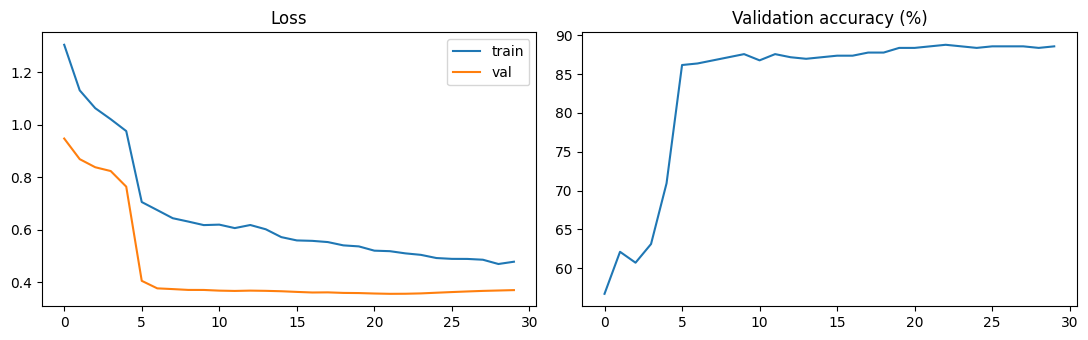

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(hist["tr_loss"], label="train"); ax[0].plot(hist["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist["val_acc"]); ax[1].set_title("Validation accuracy (%)")
plt.tight_layout(); plt.show()

## Final evaluation on the holdout set (run once)
Uses the best saved EMA weights + light TTA (original + two tiny rotations).

Holdout accuracy (TTA): 88.59%

              precision    recall  f1-score   support

        0_MI     0.7820    0.7324    0.7564       142
1_History_MI     1.0000    0.9296    0.9635       213
  2_Abnormal     0.8425    0.8662    0.8542       142
    3_Normal     0.8737    0.9719    0.9202       178

    accuracy                         0.8859       675
   macro avg     0.8745    0.8750    0.8736       675
weighted avg     0.8877    0.8859    0.8855       675



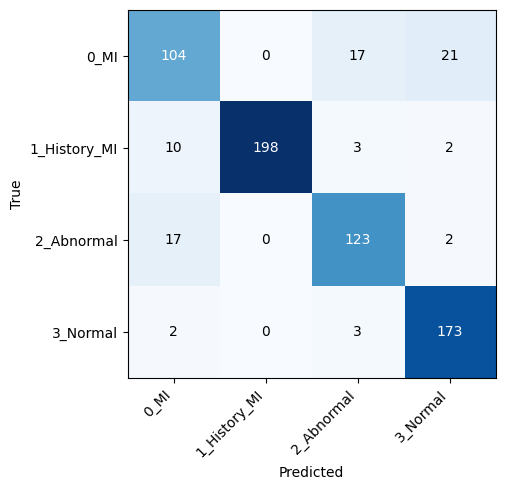

In [ ]:
best = build_model().to(device)
best.load_state_dict(torch.load(SAVE_PATH, map_location=device))
best.eval()

@torch.no_grad()
def predict_tta(m, loader, angles=(0, 2, -2)):
    probs, ys = [], []
    for x, y in loader:
        x = x.to(device); p = 0
        for a in angles:
            xa = x if a == 0 else TF.rotate(x, a)
            with torch.autocast("cuda", enabled=use_amp):
                p = p + torch.softmax(m(xa).float(), 1)
        probs.append((p / len(angles)).cpu().numpy()); ys.extend(y.numpy())
    return np.vstack(probs), np.array(ys)

P, Y = predict_tta(best, test_loader)
pred = P.argmax(1)
print(f"Holdout accuracy (TTA): {accuracy_score(Y, pred)*100:.2f}%\n")
print(classification_report(Y, pred, target_names=class_names, digits=4))

cm = confusion_matrix(Y, pred)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(class_names)
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); plt.tight_layout(); plt.show()

## If accuracy is still lower than you want
- **Check the confusion matrix first.** `0_MI` vs `1_History_MI` is usually the hardest pair; if only those two confuse, the problem is label ambiguity, not the model.
- **Domain shift:** you combine several datasets, so train and holdout may differ in scan style/grid color. Make sure the holdout contains images from *every* source dataset, and try stronger `ColorJitter` / grayscale augmentation.
- **Duplicate/near-duplicate leakage:** if the same patient appears in multiple images, split by patient, otherwise validation looks inflated and holdout looks bad.
- Try `MODEL_NAME = "efficientnet_b2"` (9M) or `"convnext_pico"` and compare; raise `IMG_H, IMG_W` only if waveform details look blurry.